# Chặng 6 — Gaussian phát hiện bất thường trên cửa sổ host

Notebook chạy lại toàn bộ Chặng 6 trên CIC-IDS2017 (thứ Hai, thứ Tư, thứ Sáu), dùng mã trong
`src/nids/gaussian.py`. Giải thích chi tiết ở `docs/33` đến `docs/38`.

**Cần có trước:** bảng đặc trưng (`output/features/cic17_*.windows.csv`), nhãn (`nids.labeling`) và
tập (`nids.splits`). Dữ liệu và mô hình không có trong git.

Thứ tự: chọn đặc trưng (T01) → kiểm tra phân bố (T02) → huấn luyện (T03) → chọn ngưỡng trên
validation (T04) → lưu, nạp lại (T06) → đánh giá trên test bằng mô hình đã nạp lại (T05).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from nids import gaussian as g
from nids.config import load_config
from nids.labeling import load_schedule

pd.set_option("display.width", 160)
PREFIXES = [str(ROOT / "output" / "features" / f"cic17_{d}") for d in ("monday", "wednesday", "friday")]
OUT = ROOT / "output" / "notebook_06"
OUT.mkdir(parents=True, exist_ok=True)
cfg = g.gaussian_config(load_config())
rules = load_schedule()
windows = g.load_windows(PREFIXES)
print(len(windows), "cửa sổ;", cfg)

465393 cửa sổ; {'covariance': 'ledoit_wolf', 'fit_session_candidates': [['cic17_monday'], None], 'threshold': 'f1_on_dinh', 'threshold_band': 1.2, 'target_fpr': 0.01, 'fit_sessions': None}


## T01 — Mẫu normal của train và chọn đặc trưng

Chỉ dùng mẫu `normal` của tập train. Quy tắc chọn: bỏ cột trống > 50%, cột là tổng của cột khác,
cột hằng số, và cột sau trong mỗi cặp tương quan Spearman ≥ 0,95.

In [2]:
for fs in (["cic17_monday"], None):
    train = g.normal_train(windows, fs)
    feats, dropped = g.select_features(train)
    print(fs or "cả ba ngày", "-", len(train), "mẫu,", len(feats), "đặc trưng")
pd.Series(dropped, name="lý do bỏ")

['cic17_monday'] - 88929 mẫu, 14 đặc trưng


cả ba ngày - 252221 mẫu, 14 đặc trưng


incomplete_out          bằng tổng no_reply_out + rejected_out + half_o...
incomplete_ratio_out                              trống 75.3% trong train
incomplete_ratio_in                               trống 94.7% trong train
bytes_out                       tương quan Spearman 0.957 với packets_out
bytes_in                         tương quan Spearman 0.952 với packets_in
dst_host_ports                    tương quan Spearman 0.988 với dst_hosts
Name: lý do bỏ, dtype: object

## T02 — Phân bố trước và sau biến đổi

Yeo-Johnson cho cột liên tục, log(1 + x) cho cột có ≥ 90% giá trị 0, rồi chuẩn hóa. So phân vị
của d² với χ²(14): nếu dữ liệu đúng Gaussian thì hai bên phải gần nhau.

In [3]:
train_mon = g.normal_train(windows, ["cic17_monday"])
feats_mon, _ = g.select_features(train_mon)
cmp = g.compare_transforms(train_mon, feats_mon)
pd.DataFrame({k: {"|skew| trung vị": cmp[k]["skew_tri_tuyet_doi_trung_vi"],
                  "chỉ số điều kiện": round(cmp[k]["chi_so_dieu_kien"], 1),
                  **{f"d² {q}": v for q, v in cmp[k]["d2_phan_vi"].items()}}
              for k in ("giu_nguyen", "log1p", "yeo_johnson_va_log")}).T.assign(
    **{f"χ² {q}": v for q, v in cmp["giu_nguyen"]["chi2_phan_vi"].items()})

,|skew| trung vị,chỉ số điều kiện,d² 0.5,d² 0.9,d² 0.99,d² 0.999,χ² 0.5,χ² 0.9,χ² 0.99,χ² 0.999
giu_nguyen,10.521,2389.8,2.48,18.95,175.81,917.96,13.34,21.06,29.14,36.12
log1p,1.967,88.2,6.36,22.85,102.32,529.83,13.34,21.06,29.14,36.12
yeo_johnson_va_log,1.041,62.7,6.93,22.49,97.89,533.02,13.34,21.06,29.14,36.12


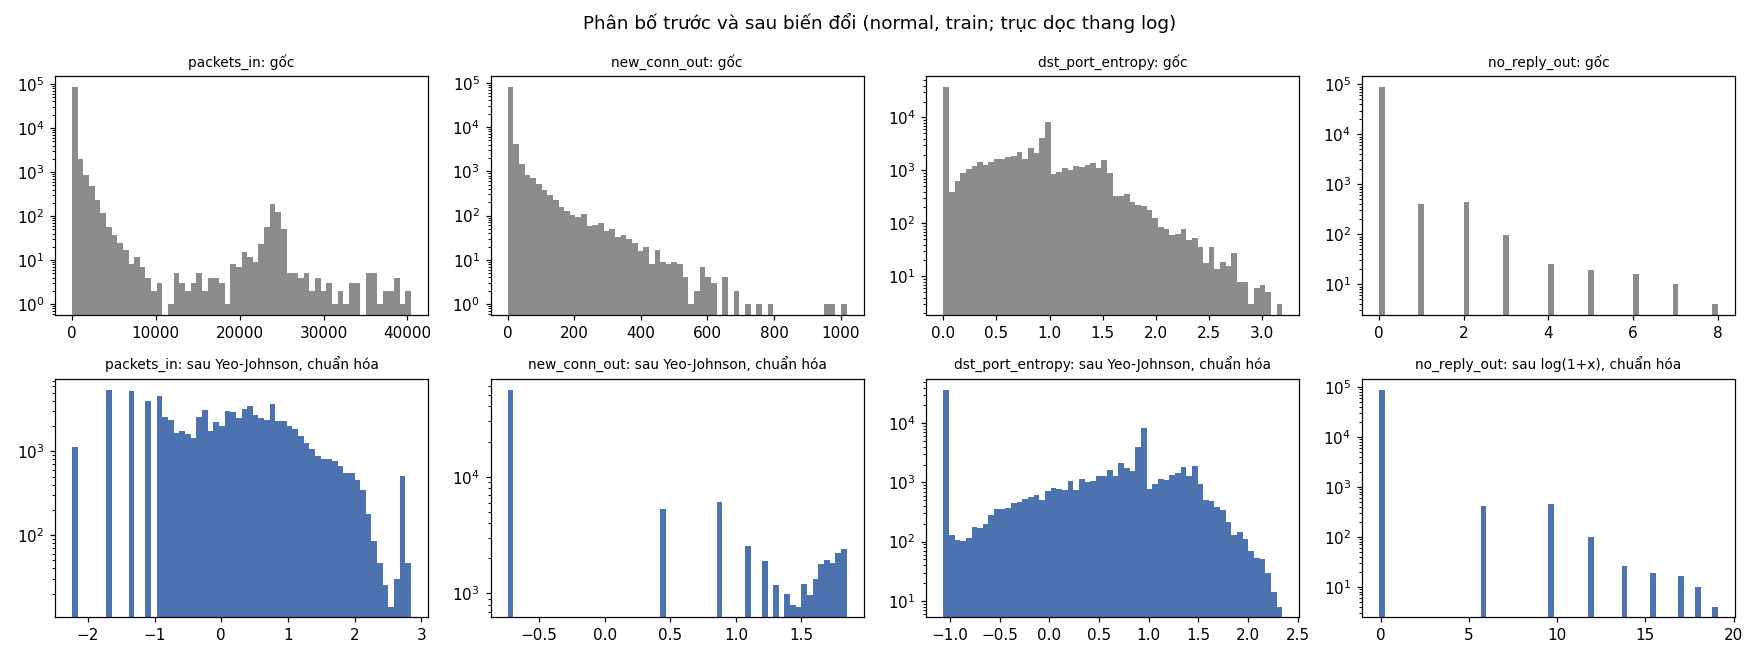

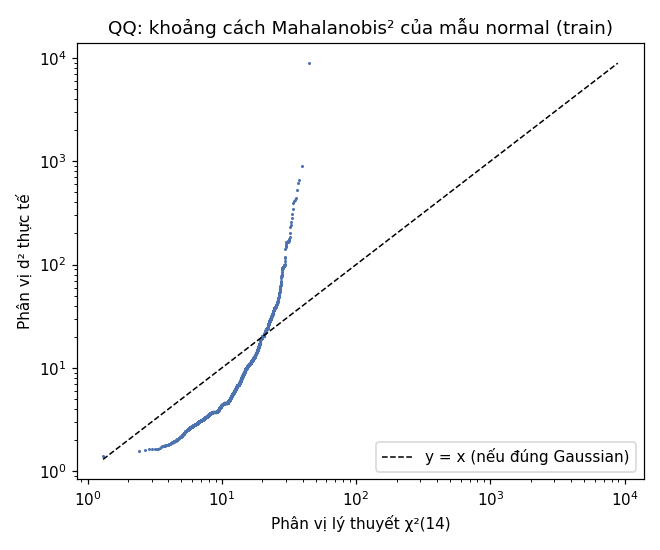

In [4]:
for f in g.plot_distribution(train_mon, feats_mon, OUT):
    display(Image(filename=str(f)))

Phần giữa khớp χ² khá tốt, nhưng **đuôi dày hơn rất nhiều** (phân vị 99%: khoảng 98 so với 29).
Vì vậy không đặt ngưỡng theo χ² mà chọn trên validation.

## T03, T04 — Huấn luyện, chọn phiên fit và ngưỡng trên validation

Hiệp phương sai Ledoit-Wolf kèm sàn trị riêng (luôn nghịch đảo được). Hai cách lấy mẫu normal
được so trên validation; ngưỡng chọn bằng "F1 ổn định" (F1 tốt nhất khi ngưỡng lệch ±20%).
Bước này **không đọc tập test**.

In [5]:
model, report, s_val, y_val = g.select_model(windows, cfg, rules)
cols = ["phien_fit", "so_mau_fit", "nguong", "precision", "recall", "f1", "fpr"]
display(pd.DataFrame(report["ung_vien"])[cols])
print("Chọn:", report["chon"], "- ngưỡng d² =", round(model.threshold, 2))
print("Hiệp phương sai:", model.info["hiep_phuong_sai"])

,phien_fit,so_mau_fit,nguong,precision,recall,f1,fpr
0,[cic17_monday],88929,69.473,0.6644,0.6984,0.6810,0.01462
1,tất cả,252221,64.651,0.6707,0.7327,0.7003,0.01491


Chọn: tất cả - ngưỡng d² = 64.65
Hiệp phương sai: {'phuong_phap': 'ledoit_wolf', 'he_so_co': 0.005547, 'tri_rieng_nho_nhat_truoc': 0.08426713906483488, 'so_tri_rieng_nang': 0, 'nguong_tri_rieng': 4.551606114291735e-06, 'chi_so_dieu_kien': 54.0140102631198}


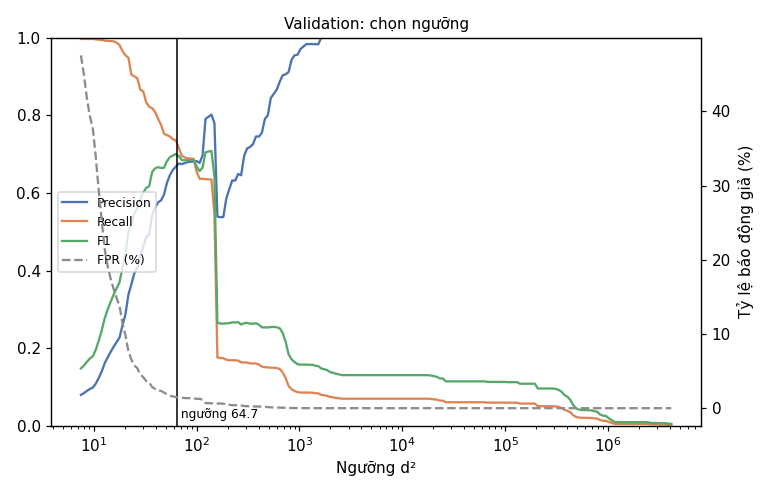

So với ngưỡng F1 lớn nhất: {'nguong': 145.597, 'precision': 0.8031, 'recall': 0.6348, 'f1': 0.7091, 'fpr': 0.00645, 'tp': 2235, 'fp': 548, 'fn': 1286, 'tn': 84410}


In [6]:
curve = g.threshold_curve(s_val, y_val)
g.plot_threshold(curve, model.threshold, OUT / "nguong.png", "Validation: chọn ngưỡng")
display(Image(filename=str(OUT / "nguong.png")))
chosen = next(r for r in report["ung_vien"] if r["phien_fit"] == report["chon"])
print("So với ngưỡng F1 lớn nhất:", chosen["so_sanh_f1_lon_nhat"])

Ngưỡng F1 lớn nhất nằm sát một "vách" (cụm cửa sổ bot có d² quanh 125–150), nên chọn ngưỡng
ổn định thấp hơn, nằm trong vùng F1 phẳng.

## T06 — Lưu và nạp lại mô hình

File joblib chứa cả phép biến đổi (λ của Yeo-Johnson, trung bình, độ lệch chuẩn), trung bình,
hiệp phương sai và ngưỡng. File `.json` đi kèm ghi thông tin để đọc không cần Python.

In [7]:
path = g.save_model(model, OUT / "gaussian_windows.joblib", cfg)
loaded = g.load_model(path)
print("Nạp lại:", type(loaded).__module__, type(loaded).__name__, "- ngưỡng", round(loaded.threshold, 2))
val = g.labeled(windows)
val = val[val["split"] == "validation"]
print("Điểm validation giống hệt:", np.allclose(loaded.score(val), s_val))

Nạp lại: nids.gaussian GaussianDetector - ngưỡng 64.65


Điểm validation giống hệt: True


## T05 — Đánh giá trên test bằng mô hình đã nạp lại

In [8]:
data = g.labeled(windows)
test = data[data["split"] == "test"]
res = g.evaluate(loaded, test, rules)
print("Test:", res["tong"], "AUC", res["auc"], "AP", res["ap"])
pd.DataFrame(res["theo_phien"]).T[["so_mau", "so_anomaly", "precision", "recall", "f1", "fpr",
                                   "dot_bao_dong_gia_moi_gio"]]

Test: {'precision': 0.7334, 'recall': 0.727, 'f1': 0.7302, 'fpr': 0.0142, 'tp': 3906, 'fp': 1420, 'fn': 1467, 'tn': 98568} AUC 0.9765 AP 0.7363


,so_mau,so_anomaly,precision,recall,f1,fpr,dot_bao_dong_gia_moi_gio
cic17_friday,41646.0,4226.0,0.8911,0.8093,0.8482,0.01117,16.6
cic17_monday,32275.0,0.0,0.0000,0.0000,0.0000,0.01283,42.1
cic17_wednesday,31440.0,1147.0,0.4525,0.4237,0.4376,0.01941,12.4


,so_mau,recall
DoS slowloris,318.0,0.9119
Bot,3554.0,0.8633
DoS Hulk,190.0,0.7053
PortScan,466.0,0.5365
DDoS,206.0,0.4951
DoS Slowhttptest,213.0,0.2770
DoS GoldenEye,24.0,0.1250
Heartbleed,402.0,0.0000


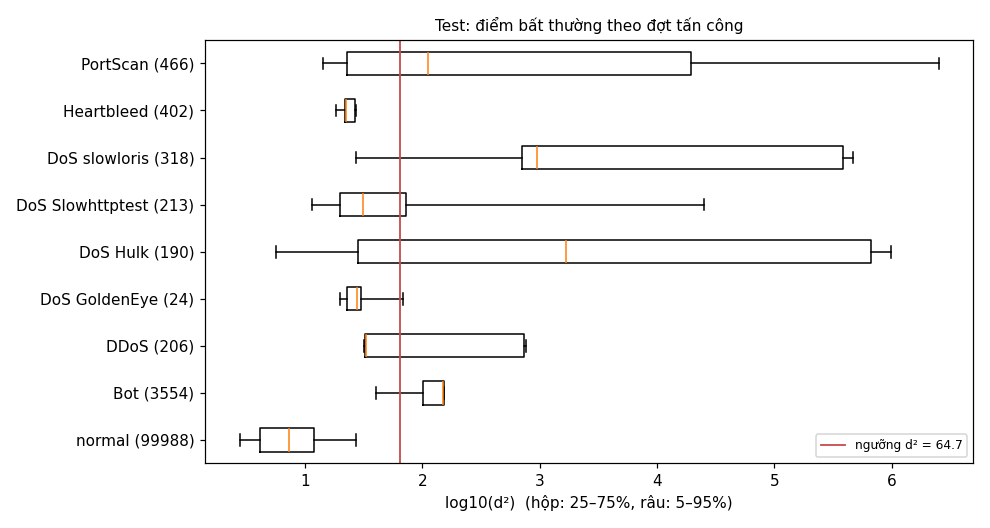

In [9]:
display(pd.DataFrame(res["recall_theo_dot"]).T.sort_values("recall", ascending=False))
g.plot_test_scores(loaded, test, rules, OUT / "test_theo_dot.png")
display(Image(filename=str(OUT / "test_theo_dot.png")))

## Hạn chế của giả định Gaussian

1. **Ngưỡng lý thuyết χ² dùng không được**: báo động giả gấp nhiều lần dự tính.

In [10]:
pd.DataFrame({k: v for k, v in res.items() if k.startswith("neu_dung_nguong_chi2")}).T[
    ["nguong", "precision", "recall", "f1", "fpr"]]

,nguong,precision,recall,f1,fpr
neu_dung_nguong_chi2_0.99,29.14,0.5145,0.8405,0.6383,0.04263
neu_dung_nguong_chi2_0.999,36.12,0.6101,0.8003,0.6924,0.02748


2. **Một Gaussian chỉ có một đỉnh**, trong khi mạng có nhiều kiểu host. So với Gaussian bỏ
   tương quan và hỗn hợp 8 Gaussian (cùng biến đổi, cùng mẫu fit, ngưỡng chọn cùng cách trên
   validation):

In [11]:
train_all = g.normal_train(windows, loaded.info["phien_fit"])
checks = g.assumption_checks(loaded, train_all, val, test)
pd.DataFrame({k: {"F1 validation": v["f1_validation"], **{f"{m} test": v["test"][m] for m in
              ("precision", "recall", "f1", "fpr")}, "AUC test": v["auc_test"], "AP test": v["ap_test"]}
              for k, v in checks.items()}).T

,F1 validation,precision test,recall test,f1 test,fpr test,AUC test,AP test
gaussian_day_du,0.7003,0.7334,0.7270,0.7302,0.01420,0.9765,0.7363
gaussian_duong_cheo,0.6851,0.7349,0.6950,0.7144,0.01347,0.9249,0.6817
hon_hop_8_gaussian,0.7424,0.9007,0.6838,0.7774,0.00405,0.9782,0.8294


3. **Cột gần như toàn 0** (kết nối không hoàn tất) không thể thành dạng chuông; chúng gây phần
   lớn báo động giả nhưng cũng là tín hiệu quét cổng mạnh nhất.
4. **Tấn công trông bình thường** về lưu lượng (Heartbleed, phía bên tấn công sau NAT, DoS chậm)
   không bắt được bằng thống kê lưu lượng.

Phân tích đầy đủ: `docs/37_gaussian_danh_gia.md`.

## Thuật ngữ

| Thuật ngữ | Giải thích |
|---|---|
| Gaussian đa biến | Mô hình dữ liệu bình thường bằng trung bình và ma trận hiệp phương sai |
| d² (Mahalanobis) | Điểm bất thường: khoảng cách tới trung bình có tính dao động và tương quan |
| Ngưỡng | Mức d² từ đó trở lên thì báo động |
| Precision, Recall, F1 | Tỷ lệ báo đúng / tỷ lệ bắt được / trung bình điều hòa của hai số |
| FPR | Tỷ lệ cửa sổ bình thường bị báo nhầm |
| χ² | Phân bố lý thuyết của d² nếu dữ liệu đúng Gaussian |
| Hỗn hợp Gaussian | Mô hình gồm nhiều Gaussian cho nhiều kiểu hành vi |